# Classificação MILCO/NOMBO — ConvNeXt-Pico: diagnóstico da fusão e triagem de parceiros (v3)

Continuação da v2. Na v2 o **ConvNeXt-Pico sozinho** superou a fusão com MobileNetV2 (como no repositório
`MODELS/TESTES_RECORTES_YOLO_CONVNEXT`). Esta versão responde **por quê** e procura **parceiros melhores**,
sem GhostNet.

## Experimentos (todos com 3 sementes por padrão, para medir o ruído)

| Seção | O que faz | Pergunta que responde |
|---|---|---|
| 8 | Treina ConvNeXt-Pico e cada parceiro **sozinhos** + triagem | O parceiro é forte o bastante para valer a pena? |
| 9 | **Fusão tardia** (média das probabilidades dos modelos solo) | O problema é o parceiro ou é concatenar features e treinar junto? |
| 10 | **Fusão precoce** (concat de features): `b12` (receita da v2), `b32` e `robusta` | Batch/BatchNorm explicam? Uma fusão com salvaguardas resolve? |
| 11 | **Fusão de visões**: ConvNeXt com margem 15% + ConvNeXt com margem 50% | Contexto extra ajuda mais que outra arquitetura? |
| 12 | Diagnósticos: correlação, confiança, ablação de ramos, escala das features | Qual ramo decide? Há superconfiança? |
| 13 | Resumo geral + intervalo de confiança (bootstrap) das diferenças | A diferença é real ou ruído? |
| 14–16 | Modelo final (configurável), avaliação, grade 4x4 e pipeline YOLO | — |

**Protocolo:** todas as escolhas (triagem, melhor configuração) usam a **validação** (AUC MILCO×NOMBO).
O teste (109 objetos) é só para relatar — e, por ser pequeno, as comparações trazem IC de 95% por bootstrap.

**Retomável:** cada treino salva checkpoint + probabilidades em `checkpoints/v3/`. Se a execução cair,
rode de novo: o que já terminou é carregado do cache (`RETOMAR = True`). Para refazer algo, apague os arquivos
correspondentes em `checkpoints/v3/`.

**Tempo:** depende da GPU. Para um teste rápido use `SEEDS = [42]` e reduza `PARCEIROS`.

## Por que a v1 (ConvNeXt-Tiny + MobileNetV2) deu 0,76 e o repositório cita 0,89

**1. O 0,89 não é de uma fusão.** No repositório, o resultado alto é do **ConvNeXt-Pico sozinho**
(`b1_convnextpico_224`: acurácia de teste 0,899; 0,908 com TTA). A fusão ConvNeXt-Pico + MobileNetV2
do próprio repositório (`b4_fusao_convnext_mnv2`) teve **0,761 no teste** — praticamente igual aos 0,7615
da v1. Ou seja, a v1 não estava "quebrada": reproduziu o que a fusão com MobileNetV2 faz naquele setup.

**2. A receita de treino era outra** (isso afeta principalmente o ConvNeXt sozinho e explica o
sobreajuste da v1: loss de treino ~0,002 enquanto a de validação subia):

| | v1 (seu notebook) | repositório |
|---|---|---|
| Backbone | `convnext_tiny` (28M, in12k→in1k) | `convnext_pico` (9M, in1k) |
| Congelamento | backbones congelados, depois só as últimas camadas | **tudo treinável desde a 1ª época** |
| Otimizador | AdamW lr 1e-3 → 1e-4, wd 1e-4, ReduceLROnPlateau | AdamW lr 2e-4 (backbone) / 2e-3 (cabeça), **wd 0,05**, cosine + warmup 5% |
| Augmentation | flip + ColorJitter | flip + afim (rot ±10°, zoom ±10%, desloc. 5%) + brilho/contraste ±20% |
| Pesos de classe | inverso da frequência | suavizados (`soften` 0,6) |
| Escolha do checkpoint | menor loss de validação | **maior AUC MILCO×NOMBO na validação** |
| Épocas / batch | 20 + 20 (paciência 8) / 16 | 30 (paciência 8) / 32 (12 na fusão) |

**3. Ruído estatístico.** O teste tem só 109 objetos (34 NOMBO): cada recorte errado vale ~0,9 ponto de
acurácia e o erro-padrão é ~3–4 pontos. Diferenças de 2–4 pontos entre execuções são normais; o repositório
usa 3 sementes nos finalistas justamente por isso.

**Expectativa honesta:** com esta receita o modo `convnext` deve ficar perto de 0,90; o modo `fusao`, perto de
0,76–0,81, como no repositório. Se quiser uma fusão que supere o ConvNeXt sozinho, é preciso um experimento
novo (veja as sugestões ao final do notebook).

## 1. Imports

In [1]:
# !pip install torch torchvision timm scikit-learn matplotlib pillow ultralytics --quiet

import os
import glob
import math
import gc
import json
import time
from itertools import combinations
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms as T

import timm

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report, roc_auc_score, f1_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

from scipy.stats import spearmanr

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cuda



## 2. Configuração — duas pastas separadas

Este notebook usa **duas pastas distintas**, para não misturar o que pertence à detecção (YOLO)
com o que pertence à classificação (ConvNeXt+MobileNetV2):

- **`DETECCAO_DIR`**: a pasta onde o notebook de detecção já rodou — contém `yolo_dataset/`
  (imagens + labels remapeados pra classe única `object`) e `runs/` (pesos `best.pt` dos
  Modelos A/B treinados). **Só leitura** aqui — nada neste notebook escreve dentro dela.
- **`CLASSIFICACAO_DIR`**: a pasta nova onde este notebook (e os artefatos que ele gera) vivem —
  vai receber `crops_dataset/` (os recortes com a classe real) e `checkpoints/` (os pesos do
  classificador de fusão treinado aqui).

`BOX_FORMAT` precisa ser **o mesmo** que você confirmou no diagnóstico visual da Seção 3.1 do
notebook de detecção (`"center"` ou `"corner"`) — senão os recortes saem deslocados.


In [2]:
DETECCAO_DIR = Path("D:/testte/SEPARACAO_MODELS/TESTE_BOX_YOLO/work")   # <-- pasta do notebook de detecção (YOLO)
CLASSIFICACAO_DIR = Path("D:/testte/data-science-notebooks/MODELS/TESTE_CONVNEXT")      # <-- pasta nova deste notebook

RAW_DATA_DIR = "D:/testte/SEPARACAO_MODELS/raw_data"   # anotações originais (antes do remapeamento)
BOX_FORMAT = "center"                                   # <-- ajuste conforme o diagnóstico visual do outro notebook

YOLO_DIR = DETECCAO_DIR / "yolo_dataset"          # gerado pelo notebook de detecção (só leitura)
CROPS_DIR = CLASSIFICACAO_DIR / "crops_dataset"   # gerado por ESTE notebook
CHECKPOINT_DIR = CLASSIFICACAO_DIR / "checkpoints"  # checkpoints do classificador (não do YOLO)

CLASSIFICACAO_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["MILCO", "NOMBO"]          # 0=MILCO, 1=NOMBO na anotação original
CROP_MARGIN = 0.15                        # 15% de contexto extra ao redor da caixa

# ---------------- Receita de treino (igual à v2 / crop_harness.py do repositório) ----------------
IMG_SIZE = 224
FUSION_IMG_SIZE = IMG_SIZE             # alias (compatibilidade)
EPOCHS = 30
PATIENCE = 8                           # early stopping sobre a AUC de validação
BATCH_SOLO = 32
LR = 2e-4                              # backbone; a cabeça usa LR * HEAD_LR_MULT
HEAD_LR_MULT = 10.0
WEIGHT_DECAY = 0.05
WARMUP_FRAC = 0.05                     # warmup linear + decaimento cosine por passo
SOFTEN = 0.6                           # pesos de classe suavizados: 1 + SOFTEN * (peso_inverso - 1)

# ---------------- Experimentos da v3 ----------------
SEEDS = [42, 43, 44]                   # 1 semente = rápido, porém muito ruidoso (teste de 109 objetos)
RETOMAR = True                         # reaproveita treinos já concluídos (checkpoints/v3/)
VERBOSO = False                        # True = imprime todas as épocas

BACKBONE_BASE = "convnext_pico"

# Parceiros a triar (nomes do timm). Os que falharem ao carregar são pulados com aviso.
PARCEIROS = [
    "tf_efficientnetv2_b0",   # melhor parceiro da fusão no repositório (referência)
    "regnety_016",            # CNN com outro design (SE + convolução em grupos), pequena
    "densenet121",            # conexões densas / reuso de features
    "resnet50",               # clássico estável com poucos dados
    "edgenext_small",         # híbrido CNN + atenção
    "mobilevitv2_100",        # híbrido CNN + transformer leve
    "mobilenetv2_100",        # o parceiro da v2 (controle)
]
TRIAGEM_MARGEM = 0.03                  # parceiro passa se AUC val média >= AUC val do ConvNeXt - margem
FUSAO_TOP_K = 1                        # quantos parceiros aprovados entram na fusão precoce
CONTROLE_FUSAO = "mobilenetv2_100"     # sempre testado na fusão precoce p/ comparar com a v2 (None = desliga)

# Variantes da fusão precoce (concatenação de features).
#   b12      = receita da v2 (batch 12)
#   b32      = mesma coisa com batch 32 (isola o efeito do BatchNorm/ruído do batch pequeno)
#   robusta  = parceiro com LR 4x menor, BatchNorm do parceiro em eval, dropout de ramo e LayerNorm nas features
FUSAO_VARIANTES = {
    "b12":     dict(batch_size=12),
    "b32":     dict(batch_size=32),
    "robusta": dict(batch_size=32, lr_mult_parceiro=0.25, bn_eval_parceiro=True,
                    branch_dropout=0.3, norm_features=True),
}

RODAR_FUSAO_TARDIA  = True
RODAR_FUSAO_PRECOCE = True
RODAR_MULTI_MARGEM  = True             # fusão de visões (margem 15% + margem MARGEM_ALT)
MARGEM_ALT = 0.5

# Modelo usado nas Seções 14-16 (avaliação final, grade 4x4 e pipeline YOLO): média das probabilidades de
# TODAS as sementes de cada tag listada. Tags: "solo_<backbone>" ou "fusao_<base>+<parceiro>_<variante>".
# Obs.: não use a tag de margem alternativa aqui (o pipeline YOLO recorta com CROP_MARGIN).
FINAL_MODELOS = ["solo_convnext_pico"]

V3_DIR = CHECKPOINT_DIR / "v3"
V3_DIR.mkdir(parents=True, exist_ok=True)

assert YOLO_DIR.exists(), (
    f"Não encontrei {YOLO_DIR}. Rode primeiro o notebook de detecção "
    "(sonar_deteccao_comparacao_modelos_V3_AA.ipynb) até a Seção 3, e confirme se DETECCAO_DIR "
    "aponta para a mesma pasta usada lá (WORK_DIR daquele notebook)."
)


## 3. Recuperando a classe real (MILCO/NOMBO) das anotações originais

`parse_annotation_com_classe` é a mesma lógica do `parse_annotation()` do notebook de detecção,
só que devolve também `classe` (em vez de descartá-la). Indexamos todos os `.txt` originais uma
vez por nome de arquivo (stem), para casar rapidamente com cada imagem que já está em
`yolo_dataset/images/{split}/`.


In [3]:

def parse_annotation_com_classe(txt_path, img_w, img_h, box_format="center"):
    resultados = []
    if not os.path.exists(txt_path):
        return resultados
    with open(txt_path, "r") as f:
        for line in f.read().strip().splitlines():
            if not line.strip():
                continue
            parts = line.strip().split()
            cls = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:5])

            if box_format == "center":
                xc, yc, bw, bh = x, y, w, h
            elif box_format == "corner":
                bw, bh = w, h
                xc, yc = x + w / 2, y + h / 2
            else:
                raise ValueError("box_format deve ser 'center' ou 'corner'")

            xmin = (xc - bw / 2) * img_w
            xmax = (xc + bw / 2) * img_w
            ymin = (yc - bh / 2) * img_h
            ymax = (yc + bh / 2) * img_h
            resultados.append((cls, xmin, ymin, xmax, ymax))
    return resultados


def indexar_anotacoes_originais(raw_dir):
    txt_paths = glob.glob(os.path.join(raw_dir, "**", "*.txt"), recursive=True)
    return {Path(p).stem: p for p in txt_paths}


indice_anotacoes = indexar_anotacoes_originais(RAW_DATA_DIR)
print(f"{len(indice_anotacoes)} anotações originais indexadas em {RAW_DATA_DIR}")


1170 anotações originais indexadas em D:/testte/SEPARACAO_MODELS/raw_data



## 4. Construindo o dataset de recortes

Para cada imagem já presente em `yolo_dataset/images/{train,val,test}/`, busca a anotação
**original** pelo mesmo nome de arquivo, recorta cada objeto (com margem de contexto) e salva em
`crops_dataset/{split}/{MILCO ou NOMBO}/{stem}_{idx}.jpg` — estrutura pronta para
`torchvision.datasets.ImageFolder`.


In [4]:

def construir_dataset_recortes(yolo_dir, raw_dir, out_dir, box_format="center",
                                margin=CROP_MARGIN, class_names=CLASS_NAMES, tamanho_minimo_px=4):
    yolo_dir, out_dir = Path(yolo_dir), Path(out_dir)
    indice = indexar_anotacoes_originais(raw_dir)

    contagens = {split: {c: 0 for c in class_names} for split in ("train", "val", "test")}
    sem_anotacao_original = []
    classes_invalidas = 0
    recortes_degenerados = 0

    for split in ("train", "val", "test"):
        img_dir = yolo_dir / "images" / split
        if not img_dir.exists():
            continue
        for img_path in sorted(img_dir.glob("*.jpg")):
            stem = img_path.stem
            txt_path = indice.get(stem)
            if txt_path is None:
                sem_anotacao_original.append(stem)
                continue

            img = Image.open(img_path).convert("RGB")
            w, h = img.size
            anotacoes = parse_annotation_com_classe(txt_path, w, h, box_format=box_format)

            for idx, (cls, xmin, ymin, xmax, ymax) in enumerate(anotacoes):
                if cls < 0 or cls >= len(class_names):
                    classes_invalidas += 1
                    continue

                nome_classe = class_names[cls]
                bw, bh = xmax - xmin, ymax - ymin
                xmin_m = xmin - bw * margin
                ymin_m = ymin - bh * margin
                xmax_m = xmax + bw * margin
                ymax_m = ymax + bh * margin

                # Arredonda para inteiro ANTES de cortar (é isso que o PIL faz internamente;
                # comparar só os floats deixa passar caixas de <1px que viram recorte vazio).
                xmin_i = max(0, int(round(xmin_m)))
                ymin_i = max(0, int(round(ymin_m)))
                xmax_i = min(w, int(round(xmax_m)))
                ymax_i = min(h, int(round(ymax_m)))

                # Garante um recorte com pelo menos `tamanho_minimo_px` de largura/altura,
                # expandindo para o lado que ainda cabe na imagem.
                if xmax_i - xmin_i < tamanho_minimo_px:
                    falta = tamanho_minimo_px - (xmax_i - xmin_i)
                    xmin_i = max(0, xmin_i - falta // 2)
                    xmax_i = min(w, xmin_i + tamanho_minimo_px)
                    xmin_i = max(0, xmax_i - tamanho_minimo_px)
                if ymax_i - ymin_i < tamanho_minimo_px:
                    falta = tamanho_minimo_px - (ymax_i - ymin_i)
                    ymin_i = max(0, ymin_i - falta // 2)
                    ymax_i = min(h, ymin_i + tamanho_minimo_px)
                    ymin_i = max(0, ymax_i - tamanho_minimo_px)

                if xmax_i <= xmin_i or ymax_i <= ymin_i:
                    recortes_degenerados += 1
                    continue

                crop = img.crop((xmin_i, ymin_i, xmax_i, ymax_i))
                destino = out_dir / split / nome_classe
                destino.mkdir(parents=True, exist_ok=True)
                crop.save(destino / f"{stem}_{idx}.jpg")
                contagens[split][nome_classe] += 1

    if sem_anotacao_original:
        print(f"AVISO: {len(sem_anotacao_original)} imagens sem anotação original correspondente "
              f"(puladas). Primeiras: {sem_anotacao_original[:5]}")
    if classes_invalidas:
        print(f"AVISO: {classes_invalidas} anotações com índice de classe fora de "
              f"CLASS_NAMES={class_names} (puladas).")
    if recortes_degenerados:
        print(f"AVISO: {recortes_degenerados} anotações geraram caixa vazia mesmo após o ajuste "
              f"mínimo (puladas) — vale checar se BOX_FORMAT ('{box_format}') está correto.")

    return contagens


contagens = construir_dataset_recortes(YOLO_DIR, RAW_DATA_DIR, CROPS_DIR, box_format=BOX_FORMAT)

print("\nDistribuição de recortes por split e classe:")
for split, c in contagens.items():
    total = sum(c.values())
    print(f"  {split:5s} -> {c} (total: {total})")



Distribuição de recortes por split e classe:
  train -> {'MILCO': 312, 'NOMBO': 172} (total: 484)
  val   -> {'MILCO': 50, 'NOMBO': 25} (total: 75)
  test  -> {'MILCO': 75, 'NOMBO': 34} (total: 109)



## 5. Checagem do desbalanceamento

Confirma visualmente a proporção MILCO x NOMBO em cada split (o dataset original tem ~437 MILCO
para ~231 NOMBO — desbalanceado). Esses pesos serão usados na loss do treinamento (Seção 8).


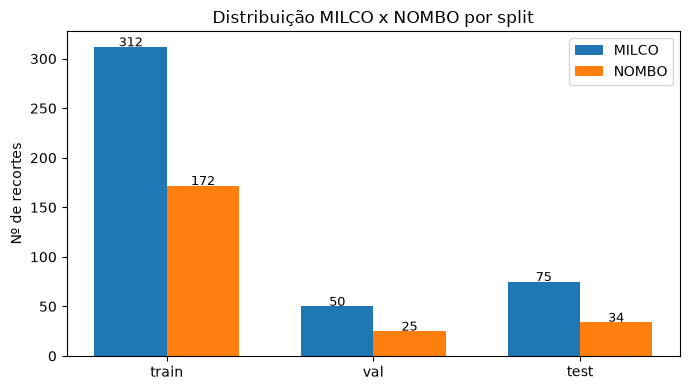

In [5]:

fig, ax = plt.subplots(figsize=(7, 4))
splits = list(contagens.keys())
x = np.arange(len(splits))
largura = 0.35

for i, classe in enumerate(CLASS_NAMES):
    valores = [contagens[s][classe] for s in splits]
    ax.bar(x + i * largura, valores, largura, label=classe)
    for xi, v in zip(x + i * largura, valores):
        ax.text(xi, v + 0.5, str(v), ha="center", fontsize=9)

ax.set_xticks(x + largura / 2)
ax.set_xticklabels(splits)
ax.set_ylabel("Nº de recortes")
ax.set_title("Distribuição MILCO x NOMBO por split")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Datasets e DataLoaders (PyTorch `ImageFolder`)

In [6]:
# ImageFolder ordena as classes alfabeticamente: MILCO (0) antes de NOMBO (1).
# O Dataset só redimensiona e converte para tensor em [0,1]; a augmentation roda em lote na GPU (Seção 7)
# e cada backbone normaliza com a média/desvio do seu próprio pré-treino (dentro do modelo).
transform_eval = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
])
transform_train = transform_eval


def carregar_tensores(ds):
    # poucos recortes (centenas): cabem inteiros na memória
    X = torch.stack([ds[i][0] for i in range(len(ds))])
    y = torch.tensor([ds.samples[i][1] for i in range(len(ds))], dtype=torch.long)
    return X, y


def montar_dados(crops_dir):
    d = {}
    for s in ("train", "val", "test"):
        ds = datasets.ImageFolder(Path(crops_dir) / s, transform=transform_eval)
        assert list(ds.class_to_idx.keys()) == CLASS_NAMES, (
            f"Ordem das classes do ImageFolder ({ds.class_to_idx}) difere de CLASS_NAMES={CLASS_NAMES}")
        d["ds_" + s] = ds
        d["X_" + s], d["y_" + s] = carregar_tensores(ds)
    cont = np.bincount(d["y_train"].numpy(), minlength=len(CLASS_NAMES))
    inverso = cont.sum() / (len(CLASS_NAMES) * np.maximum(cont, 1))
    d["pesos"] = torch.tensor(1 + SOFTEN * (inverso - 1), dtype=torch.float32)   # pesos suavizados
    print(f"[{Path(crops_dir).name}] treino {len(d['X_train'])} | val {len(d['X_val'])} | teste {len(d['X_test'])}"
          f" | contagem treino {cont.tolist()} | pesos {d['pesos'].tolist()}")
    return d


DADOS = montar_dados(CROPS_DIR)

# nomes usados pelas células da grade 4x4 / pipeline
ds_train_cls, ds_val_cls, ds_test_cls = DADOS["ds_train"], DADOS["ds_val"], DADOS["ds_test"]
Y_VAL, Y_TEST = DADOS["y_val"].numpy(), DADOS["y_test"].numpy()

[crops_dataset] treino 484 | val 75 | teste 109 | contagem treino [312, 172] | pesos [0.8653846383094788, 1.2441860437393188]


## 7. Modelo e treino (receita do repositório, generalizada)

`ClassificadorRecortes` aceita 1 ou mais backbones. Com 1 backbone a cabeça é `Dropout(0.3) → Linear`; com 2+,
as features são concatenadas e passam por `Linear(256) → ReLU → Dropout(0.4) → Linear`. Opções usadas só nas
variantes de fusão:

- `norm_features`: `LayerNorm` em cada ramo antes da concatenação (iguala as escalas das features);
- `branch_dropout`: no treino, com probabilidade *p* por amostra, zera as features de **um** ramo sorteado (a
  cabeça aprende a não depender de um só ramo; no teste os dois ramos ficam ativos);
- por ramo: multiplicador de LR e BatchNorm em modo `eval` (`lr_mult`, `bn_eval`).

O treino é o da v2: fine-tuning completo, AdamW (LR da cabeça ×10, wd 0,05), cosine com warmup, augmentation em
lote (flip horizontal + afim + brilho/contraste; **sem flip vertical**), checkpoint pela **AUC de validação**.

In [7]:
def criar_backbone(nome):
    b = timm.create_model(nome, pretrained=True, num_classes=0)   # saída = vetor global (após pooling)
    dc = timm.data.resolve_data_config({}, model=b)
    b.register_buffer("mu", torch.tensor(dc["mean"]).view(1, 3, 1, 1), persistent=False)
    b.register_buffer("sd", torch.tensor(dc["std"]).view(1, 3, 1, 1), persistent=False)
    return b


class ClassificadorRecortes(nn.Module):
    """Entrada: imagens em [0,1]. Cada backbone normaliza com a média/desvio do seu pré-treino."""
    def __init__(self, nomes, num_classes=2, branch_dropout=0.0, norm_features=False):
        super().__init__()
        self.nomes = list(nomes)
        self.branch_dropout = branch_dropout
        self.backbone = nn.ModuleList([criar_backbone(n) for n in self.nomes])

        # tamanho REAL das features (não confiar em num_features): mede com um tensor fake do tamanho de entrada
        # (alguns modelos com atenção em janelas exigem o tamanho certo).
        self.eval()
        with torch.no_grad():
            self.dims = [b(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).shape[1] for b in self.backbone]
        self.train()
        nf = sum(self.dims)

        self.norms = nn.ModuleList([nn.LayerNorm(d) for d in self.dims]) if norm_features else None
        if len(self.nomes) == 1:
            self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(nf, num_classes))
        else:
            self.head = nn.Sequential(nn.Linear(nf, 256), nn.ReLU(inplace=True),
                                      nn.Dropout(0.4), nn.Linear(256, num_classes))

    def features(self, x):
        feats = [b((x - b.mu) / b.sd) for b in self.backbone]
        if self.norms is not None:
            feats = [n(f) for n, f in zip(self.norms, feats)]
        return feats

    def classificar(self, feats):
        return self.head(torch.cat(feats, dim=1))

    def forward(self, x):
        feats = self.features(x)
        if self.training and self.branch_dropout > 0 and len(feats) > 1:
            B = x.shape[0]
            soltar = torch.rand(B, device=x.device) < self.branch_dropout
            qual = torch.randint(0, len(feats), (B,), device=x.device)
            feats = [f * (1 - (soltar & (qual == k)).float().unsqueeze(1)) for k, f in enumerate(feats)]
        return self.classificar(feats)


class ConjuntoMedia(nn.Module):
    """Média das probabilidades de vários modelos. Devolve log(prob média): softmax(saída) = prob média,
    então funciona nas células que fazem torch.softmax(modelo(x), 1)."""
    def __init__(self, modelos):
        super().__init__()
        self.modelos = nn.ModuleList(modelos)

    def forward(self, x):
        p = torch.stack([torch.softmax(m(x), dim=1) for m in self.modelos]).mean(0)
        return torch.log(p.clamp_min(1e-8))


# ---------------------------------------------------------------- augmentation (porta de sonar_harness.augment)
def _afim(x, deg, scale, translate, gen):
    B, dev = x.shape[0], x.device
    r = lambda: torch.rand(B, generator=gen).to(dev)
    ang = (r() * 2 - 1) * math.radians(deg)
    sc = 1 + (r() * 2 - 1) * scale
    tx = (r() * 2 - 1) * translate * 2
    ty = (r() * 2 - 1) * translate * 2
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)


def augmentar_batch(x, gen):
    B, dev = x.shape[0], x.device
    flip = (torch.rand(B, generator=gen) < 0.5).to(dev)
    x = torch.where(flip[:, None, None, None], x.flip(-1), x)          # só flip horizontal
    x = _afim(x, deg=10, scale=0.10, translate=0.05, gen=gen)
    b = 1 + (torch.rand(B, 1, 1, 1, generator=gen).to(dev) * 2 - 1) * 0.2
    c = 1 + (torch.rand(B, 1, 1, 1, generator=gen).to(dev) * 2 - 1) * 0.2
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = ((x - m) * c + m) * b
    return x.clamp(0, 1)


def fator_lr(passo, total):
    warm = max(1, int(total * WARMUP_FRAC))
    if passo < warm:
        return (passo + 1) / warm
    prog = (passo - warm) / max(1, total - warm)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))


@torch.no_grad()
def prever(model, X, bs=64, tta=False):
    """Probabilidades [N, 2]. tta=True faz a média com a versão espelhada (flip horizontal)."""
    model.eval()
    saidas = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].to(device)
        p = torch.softmax(model(x), dim=1)
        if tta:
            p = 0.5 * (p + torch.softmax(model(x.flip(-1)), dim=1))
        saidas.append(p.cpu())
    return torch.cat(saidas).numpy()


def auc_milco_nombo(y, P):
    return float(roc_auc_score(np.asarray(y) == 0, P[:, 0]))


def _modo_treino(model, bn_eval):
    model.train()
    for i in (bn_eval or []):                      # BatchNorm do ramo i fica em eval (estatísticas congeladas)
        for m in model.backbone[i].modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()


def treinar_modelo(tag, nomes, seed, dados, batch_size=BATCH_SOLO, lr_mult=None, bn_eval=None,
                   branch_dropout=0.0, norm_features=False):
    """Treina (ou carrega do cache) um modelo. Devolve dict com metadados e probabilidades val/test/test_tta."""
    chave = f"{tag}_s{seed}"
    f_ckpt, f_probs, f_meta = V3_DIR / f"{chave}.pt", V3_DIR / f"{chave}_probs.npz", V3_DIR / f"{chave}.json"
    if RETOMAR and f_ckpt.exists() and f_probs.exists() and f_meta.exists():
        p = np.load(f_probs)
        meta = json.load(open(f_meta))
        print(f"[{chave}] carregado do cache | AUC val {meta['val_auc']:.4f}")
        return {**meta, "val": p["val"], "test": p["test"], "test_tta": p["test_tta"]}

    t0 = time.time()
    torch.manual_seed(seed); np.random.seed(seed)
    model = ClassificadorRecortes(nomes, num_classes=len(CLASS_NAMES), branch_dropout=branch_dropout,
                                  norm_features=norm_features).to(device)
    lr_mult = lr_mult or [1.0] * len(nomes)

    grupos = []
    for i, b in enumerate(model.backbone):
        grupos.append({"params": list(b.parameters()), "lr": LR * lr_mult[i], "initial_lr": LR * lr_mult[i]})
    cabeca = list(model.head.parameters()) + (list(model.norms.parameters()) if model.norms is not None else [])
    grupos.append({"params": cabeca, "lr": LR * HEAD_LR_MULT, "initial_lr": LR * HEAD_LR_MULT})
    opt = torch.optim.AdamW(grupos, lr=LR, weight_decay=WEIGHT_DECAY)

    X_tr, y_tr = dados["X_train"], dados["y_train"]
    pesos = dados["pesos"].to(device)
    passos_por_epoca = math.ceil(len(X_tr) / batch_size)
    total = passos_por_epoca * EPOCHS
    gen = torch.Generator().manual_seed(seed)

    melhor, sem_melhora, passo, melhor_ep = -1.0, 0, 0, 0
    for epoca in range(1, EPOCHS + 1):
        _modo_treino(model, bn_eval)
        perm = torch.randperm(len(X_tr), generator=gen)
        soma, n = 0.0, 0
        for k in range(passos_por_epoca):
            idx = perm[k * batch_size:(k + 1) * batch_size]
            if len(idx) < 2:          # BatchNorm não aceita lote de 1 amostra
                continue
            xb = augmentar_batch(X_tr[idx].to(device), gen)
            yb = y_tr[idx].to(device)

            f = fator_lr(passo, total)
            for g in opt.param_groups:
                g["lr"] = g["initial_lr"] * f

            loss = F.cross_entropy(model(xb), yb, weight=pesos)
            opt.zero_grad()
            loss.backward()
            opt.step()
            passo += 1
            soma += loss.item() * len(idx); n += len(idx)

        Pv = prever(model, dados["X_val"])
        auc = auc_milco_nombo(dados["y_val"].numpy(), Pv)
        acc = float((Pv.argmax(1) == dados["y_val"].numpy()).mean())
        if VERBOSO or epoca == 1 or epoca % 5 == 0:
            print(f"[{chave}] época {epoca}/{EPOCHS} loss {soma / max(1, n):.4f} | AUC val {auc:.4f} | acc val {acc:.4f}")

        if auc > melhor + 1e-4:
            melhor, sem_melhora, melhor_ep = auc, 0, epoca
            torch.save(model.state_dict(), f_ckpt)
        else:
            sem_melhora += 1
            if sem_melhora >= PATIENCE:
                break

    model.load_state_dict(torch.load(f_ckpt, map_location=device))
    out = {"val": prever(model, dados["X_val"]), "test": prever(model, dados["X_test"]),
           "test_tta": prever(model, dados["X_test"], tta=True)}
    meta = {"tag": tag, "seed": seed, "nomes": list(nomes), "batch_size": batch_size,
            "branch_dropout": branch_dropout, "norm_features": norm_features,
            "val_auc": float(melhor), "melhor_epoca": melhor_ep, "epocas": epoca,
            "treino_s": time.time() - t0}
    np.savez(f_probs, **out)
    json.dump(meta, open(f_meta, "w"))
    print(f"[{chave}] concluído em {meta['treino_s'] / 60:.1f} min | melhor AUC val {melhor:.4f} (época {melhor_ep})")

    del model, opt
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return {**meta, **out}


def carregar_modelo(tag, seed):
    meta = json.load(open(V3_DIR / f"{tag}_s{seed}.json"))
    m = ClassificadorRecortes(meta["nomes"], num_classes=len(CLASS_NAMES), norm_features=meta["norm_features"]).to(device)
    m.load_state_dict(torch.load(V3_DIR / f"{tag}_s{seed}.pt", map_location=device))
    return m.eval()


RES = {}   # RES[tag][seed] = {"val","test","test_tta" (probabilidades), "val_auc", ...}


def rodar(tag, nomes, dados=None, **kw):
    dados = DADOS if dados is None else dados
    RES.setdefault(tag, {})
    for seed in SEEDS:
        RES[tag][seed] = treinar_modelo(tag, nomes, seed, dados, **kw)

### Helpers de análise (só numpy/sklearn)

`add_linha` registra uma configuração (média ± desvio entre sementes ou pares). `Pt_ens` guarda a média das
probabilidades de teste entre as entradas e é usada só no bootstrap da Seção 13.

In [8]:
LINHAS = []   # cada linha = uma configuração avaliada


def metricas_P(P, y):
    pred = P.argmax(1)
    return {"acc": float((pred == y).mean()), "auc": auc_milco_nombo(y, P),
            "f1_nombo": float(f1_score(y == 1, pred == 1, zero_division=0)),
            "f1_macro": float(f1_score(y, pred, average="macro", zero_division=0))}


def add_linha(grupo, nome, Pv_list, Pt_list, Ptta_list):
    mt = [metricas_P(P, Y_TEST) for P in Pt_list]
    LINHAS.append({
        "grupo": grupo, "nome": nome,
        "val_auc": [auc_milco_nombo(Y_VAL, P) for P in Pv_list],
        "test_auc": [m["auc"] for m in mt],
        "test_acc": [m["acc"] for m in mt],
        "f1_nombo": [m["f1_nombo"] for m in mt],
        "test_acc_tta": [float((P.argmax(1) == Y_TEST).mean()) for P in Ptta_list],
        "Pt_ens": np.mean(Pt_list, axis=0),
    })
    LINHAS[-1]["n"] = len(Pt_list)


def _ms(v):
    v = np.asarray(v, float)
    return f"{v.mean():.3f}±{v.std():.3f}" if len(v) > 1 else f"{v.mean():.3f}      "


def imprimir_linhas(grupos=None):
    sel = [l for l in LINHAS if grupos is None or l["grupo"] in grupos]
    sel = sorted(sel, key=lambda l: -np.mean(l["val_auc"]))
    print(f"{'configuração':58s} {'AUC val':>13s} {'AUC teste':>13s} {'acc teste':>13s} {'acc TTA':>8s} {'F1 NOMBO':>9s}")
    for l in sel:
        print(f"{l['nome'][:58]:58s} {_ms(l['val_auc']):>13s} {_ms(l['test_auc']):>13s} {_ms(l['test_acc']):>13s} "
              f"{np.mean(l['test_acc_tta']):8.3f} {np.mean(l['f1_nombo']):9.3f}")


def linha_de_tag(grupo, tag, nome=None):
    E = [RES[tag][s] for s in SEEDS]
    add_linha(grupo, nome or tag, [e["val"] for e in E], [e["test"] for e in E], [e["test_tta"] for e in E])


def tardia_pareada(tag_a, tag_b, nome, grupo="fusão tardia"):
    """Média das probabilidades de a e b treinados com a MESMA semente (uma entrada por semente)."""
    Pv, Pt, Ptta = [], [], []
    for s in SEEDS:
        a, b = RES[tag_a][s], RES[tag_b][s]
        Pv.append((a["val"] + b["val"]) / 2); Pt.append((a["test"] + b["test"]) / 2)
        Ptta.append((a["test_tta"] + b["test_tta"]) / 2)
    add_linha(grupo, nome, Pv, Pt, Ptta)


def conjunto(tags, nome, grupo="conjunto"):
    """Média das probabilidades de TODAS as sementes de todas as tags (uma única entrada)."""
    L = [RES[t][s] for t in tags for s in SEEDS]
    add_linha(grupo, nome, [np.mean([e["val"] for e in L], 0)], [np.mean([e["test"] for e in L], 0)],
              [np.mean([e["test_tta"] for e in L], 0)])


def base_mais_base(tag, nome, grupo="fusão tardia"):
    """Controle justo p/ a fusão tardia: mesmo modelo com outra semente (pares de sementes diferentes)."""
    Pv, Pt, Ptta = [], [], []
    for s1, s2 in combinations(SEEDS, 2):
        a, b = RES[tag][s1], RES[tag][s2]
        Pv.append((a["val"] + b["val"]) / 2); Pt.append((a["test"] + b["test"]) / 2)
        Ptta.append((a["test_tta"] + b["test_tta"]) / 2)
    if Pv:
        add_linha(grupo, nome, Pv, Pt, Ptta)


def ic_diff_auc(Pa, Pb, y, n=2000, seed=0):
    """Bootstrap pareado (reamostra objetos do teste): média e IC95% de AUC(a) - AUC(b)."""
    rng = np.random.default_rng(seed)
    y = np.asarray(y); N = len(y); difs = []
    for _ in range(n):
        idx = rng.integers(0, N, N)
        if len(np.unique(y[idx])) < 2:
            continue
        difs.append(auc_milco_nombo(y[idx], Pa[idx]) - auc_milco_nombo(y[idx], Pb[idx]))
    return float(np.mean(difs)), np.percentile(difs, [2.5, 97.5])

## 8. Triagem: ConvNeXt-Pico e parceiros, cada um sozinho

Antes de fundir, vale saber se o parceiro é bom sozinho. No repositório, os parceiros mais fracos arrastaram a
fusão para baixo (MobileNetV2: AUC solo 0,849 → fusão 0,815). Regra de triagem: o parceiro **passa** se a AUC de
validação média (entre sementes) for no máximo `TRIAGEM_MARGEM` abaixo da do ConvNeXt-Pico.

In [9]:
tag_base = f"solo_{BACKBONE_BASE}"
print(f">>> {tag_base}")
rodar(tag_base, [BACKBONE_BASE])
linha_de_tag("solo", tag_base)

for p in PARCEIROS:
    tag = f"solo_{p}"
    print(f"\n>>> {tag}")
    try:
        rodar(tag, [p])
        linha_de_tag("solo", tag)
    except Exception as e:          # modelo indisponível no timm / sem memória etc.
        print(f"PULADO {p}: {type(e).__name__}: {e}")
        RES.pop(tag, None)

val_base = np.mean([RES[tag_base][s]["val_auc"] for s in SEEDS])
APROVADOS = []
print(f"\nAUC de validação do {BACKBONE_BASE} (média das sementes): {val_base:.4f} | corte: {val_base - TRIAGEM_MARGEM:.4f}")
for p in PARCEIROS:
    tag = f"solo_{p}"
    if tag not in RES:
        continue
    v = np.mean([RES[tag][s]["val_auc"] for s in SEEDS])
    passou = v >= val_base - TRIAGEM_MARGEM
    print(f"  {p:24s} AUC val {v:.4f}  ->  {'APROVADO' if passou else 'reprovado'}")
    if passou:
        APROVADOS.append((v, p))
APROVADOS = [p for _, p in sorted(APROVADOS, reverse=True)]
print("\nAprovados (melhor primeiro):", APROVADOS if APROVADOS else "nenhum")
print()
imprimir_linhas({"solo"})

>>> solo_convnext_pico


[solo_convnext_pico_s42] época 1/30 loss 0.6655 | AUC val 0.7144 | acc val 0.7067
[solo_convnext_pico_s42] época 5/30 loss 0.5162 | AUC val 0.8384 | acc val 0.7467
[solo_convnext_pico_s42] época 10/30 loss 0.2720 | AUC val 0.9184 | acc val 0.8800
[solo_convnext_pico_s42] época 15/30 loss 0.1048 | AUC val 0.9424 | acc val 0.8533
[solo_convnext_pico_s42] época 20/30 loss 0.0259 | AUC val 0.9084 | acc val 0.8533
[solo_convnext_pico_s42] concluído em 1.5 min | melhor AUC val 0.9424 (época 15)
[solo_convnext_pico_s43] época 1/30 loss 0.6611 | AUC val 0.7720 | acc val 0.7467
[solo_convnext_pico_s43] época 5/30 loss 0.4214 | AUC val 0.8160 | acc val 0.8400
[solo_convnext_pico_s43] época 10/30 loss 0.3737 | AUC val 0.8272 | acc val 0.7867
[solo_convnext_pico_s43] época 15/30 loss 0.1893 | AUC val 0.9184 | acc val 0.8667
[solo_convnext_pico_s43] época 20/30 loss 0.0331 | AUC val 0.9168 | acc val 0.8533
[solo_convnext_pico_s43] concluído em 1.3 min | melhor AUC val 0.9184 (época 15)
[solo_convne

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Usuário\.cache\huggingface\hub\models--timm--tf_efficientnetv2_b0.in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[solo_tf_efficientnetv2_b0_s42] época 1/30 loss 0.6779 | AUC val 0.6648 | acc val 0.5867
[solo_tf_efficientnetv2_b0_s42] época 5/30 loss 0.2610 | AUC val 0.9032 | acc val 0.8533
[solo_tf_efficientnetv2_b0_s42] época 10/30 loss 0.0994 | AUC val 0.8568 | acc val 0.7867
[solo_tf_efficientnetv2_b0_s42] concluído em 0.6 min | melhor AUC val 0.9032 (época 5)
[solo_tf_efficientnetv2_b0_s43] época 1/30 loss 0.6730 | AUC val 0.7856 | acc val 0.6400
[solo_tf_efficientnetv2_b0_s43] época 5/30 loss 0.2717 | AUC val 0.8352 | acc val 0.8667
[solo_tf_efficientnetv2_b0_s43] época 10/30 loss 0.0962 | AUC val 0.8112 | acc val 0.8800
[solo_tf_efficientnetv2_b0_s43] concluído em 0.5 min | melhor AUC val 0.9000 (época 6)
[solo_tf_efficientnetv2_b0_s44] época 1/30 loss 0.6770 | AUC val 0.6560 | acc val 0.4533
[solo_tf_efficientnetv2_b0_s44] época 5/30 loss 0.3412 | AUC val 0.8520 | acc val 0.8267
[solo_tf_efficientnetv2_b0_s44] época 10/30 loss 0.0932 | AUC val 0.8464 | acc val 0.8000
[solo_tf_efficientnetv

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Usuário\.cache\huggingface\hub\models--timm--regnety_016.tv2_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


...

[solo_resnet50_s42] época 1/30 loss 0.6819 | AUC val 0.6368 | acc val 0.6533
[solo_resnet50_s42] época 5/30 loss 0.5597 | AUC val 0.4984 | acc val 0.6133
[solo_resnet50_s42] época 10/30 loss 0.3897 | AUC val 0.8016 | acc val 0.7600
[solo_resnet50_s42] época 15/30 loss 0.2316 | AUC val 0.8032 | acc val 0.7733
[solo_resnet50_s42] época 20/30 loss 0.2222 | AUC val 0.8400 | acc val 0.7733
[solo_resnet50_s42] época 25/30 loss 0.1972 | AUC val 0.8528 | acc val 0.7867
[solo_resnet50_s42] época 30/30 loss 0.1870 | AUC val 0.8408 | acc val 0.8000
[solo_resnet50_s42] concluído em 2.5 min | melhor AUC val 0.8608 (época 26)
[solo_resnet50_s43] época 1/30 loss 0.6897 | AUC val 0.6144 | acc val 0.6533
[solo_resnet50_s43] época 5/30 loss 0.5547 | AUC val 0.6536 | acc val 0.7067
[solo_resnet50_s43] época 10/30 loss 0.3777 | AUC val 0.8208 | acc val 0.7600
[solo_resnet50_s43] época 15/30 loss 0.2816 | AUC val 0.8480 | acc val 0.8267
[solo_resnet50_s43] época 20/30 loss 0.2176 | AUC val 0.8120 | acc val

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Usuário\.cache\huggingface\hub\models--timm--edgenext_small.usi_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[solo_edgenext_small_s42] época 1/30 loss 0.6913 | AUC val 0.7176 | acc val 0.7067
[solo_edgenext_small_s42] época 5/30 loss 0.3567 | AUC val 0.9008 | acc val 0.8400
[solo_edgenext_small_s42] época 10/30 loss 0.1017 | AUC val 0.8864 | acc val 0.8667
[solo_edgenext_small_s42] época 15/30 loss 0.0175 | AUC val 0.8840 | acc val 0.8533
[solo_edgenext_small_s42] época 20/30 loss 0.0032 | AUC val 0.8760 | acc val 0.8800
[solo_edgenext_small_s42] concluído em 1.6 min | melhor AUC val 0.9112 (época 12)
[solo_edgenext_small_s43] época 1/30 loss 0.6526 | AUC val 0.6832 | acc val 0.7467
[solo_edgenext_small_s43] época 5/30 loss 0.2940 | AUC val 0.8560 | acc val 0.7867
[solo_edgenext_small_s43] época 10/30 loss 0.1148 | AUC val 0.8528 | acc val 0.8533
[solo_edgenext_small_s43] concluído em 0.9 min | melhor AUC val 0.9120 (época 6)
[solo_edgenext_small_s44] época 1/30 loss 0.6724 | AUC val 0.6696 | acc val 0.6667
[solo_edgenext_small_s44] época 5/30 loss 0.3467 | AUC val 0.8008 | acc val 0.8133
[so

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Usuário\.cache\huggingface\hub\models--timm--mobilevitv2_100.cvnets_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[solo_mobilevitv2_100_s42] época 1/30 loss 0.6908 | AUC val 0.7192 | acc val 0.6667
[solo_mobilevitv2_100_s42] época 5/30 loss 0.4186 | AUC val 0.8616 | acc val 0.8000
[solo_mobilevitv2_100_s42] época 10/30 loss 0.1939 | AUC val 0.8920 | acc val 0.8000
[solo_mobilevitv2_100_s42] época 15/30 loss 0.0956 | AUC val 0.8768 | acc val 0.8133
[solo_mobilevitv2_100_s42] concluído em 1.2 min | melhor AUC val 0.8920 (época 10)
[solo_mobilevitv2_100_s43] época 1/30 loss 0.6727 | AUC val 0.6624 | acc val 0.5733
[solo_mobilevitv2_100_s43] época 5/30 loss 0.4082 | AUC val 0.8600 | acc val 0.8267
[solo_mobilevitv2_100_s43] época 10/30 loss 0.2025 | AUC val 0.8872 | acc val 0.8267
[solo_mobilevitv2_100_s43] concluído em 0.9 min | melhor AUC val 0.9016 (época 6)
[solo_mobilevitv2_100_s44] época 1/30 loss 0.6719 | AUC val 0.7216 | acc val 0.6667
[solo_mobilevitv2_100_s44] época 5/30 loss 0.4239 | AUC val 0.8888 | acc val 0.8533
[solo_mobilevitv2_100_s44] época 10/30 loss 0.1757 | AUC val 0.9080 | acc va

## 9. Fusão tardia (média das probabilidades)

Aqui **cada modelo é treinado sozinho** (Seção 8) e só as probabilidades são combinadas. Se a fusão tardia com um
parceiro já ajuda, o parceiro tem informação útil e o problema da fusão precoce é a forma de treinar. Se nem a
tardia ajuda, o parceiro é fraco/redundante.

O controle justo é **ConvNeXt + ConvNeXt com outra semente** (linha `base+base`): um conjunto de 2 modelos
melhora um pouco por si só, então um parceiro só vale algo se superar esse controle.

In [10]:
if RODAR_FUSAO_TARDIA:
    n0 = len(LINHAS)
    base_mais_base(tag_base, f"{BACKBONE_BASE} + {BACKBONE_BASE} (outra semente)  [controle]")
    for p in PARCEIROS:
        if f"solo_{p}" in RES:
            tardia_pareada(tag_base, f"solo_{p}", f"{BACKBONE_BASE} + {p} (mesma semente)")
    conjunto([tag_base], f"{BACKBONE_BASE}: conjunto das {len(SEEDS)} sementes  [referência]", grupo="conjunto")
    for p in PARCEIROS:
        if f"solo_{p}" in RES:
            conjunto([tag_base, f"solo_{p}"], f"conjunto {len(SEEDS)}x {BACKBONE_BASE} + {len(SEEDS)}x {p}")
    imprimir_linhas({"fusão tardia", "conjunto"})
else:
    print("RODAR_FUSAO_TARDIA = False")

configuração                                                     AUC val     AUC teste     acc teste  acc TTA  F1 NOMBO
conjunto 3x convnext_pico + 3x mobilevitv2_100               0.948         0.935         0.899          0.881     0.836
conjunto 3x convnext_pico + 3x mobilenetv2_100               0.946         0.916         0.853          0.881     0.771
convnext_pico: conjunto das 3 sementes  [referência]         0.946         0.934         0.872          0.890     0.794
conjunto 3x convnext_pico + 3x densenet121                   0.946         0.944         0.899          0.899     0.831
conjunto 3x convnext_pico + 3x edgenext_small                0.940         0.933         0.881          0.890     0.806
convnext_pico + mobilenetv2_100 (mesma semente)              0.939±0.009   0.895±0.026   0.869±0.004    0.875     0.784
convnext_pico + mobilevitv2_100 (mesma semente)              0.936±0.005   0.916±0.015   0.856±0.026    0.872     0.770
convnext_pico + convnext_pico (outra sem

## 10. Fusão precoce (concatenação de features) — variantes

Para o parceiro aprovado na triagem (e o controle MobileNetV2 da v2), treina três variantes:

- **`b12`**: a receita da v2 (batch 12);
- **`b32`**: igual, com batch 32 → se melhorar, o ruído do BatchNorm com batch pequeno explicava parte da perda;
- **`robusta`**: LR do parceiro ×0,25, BatchNorm do parceiro congelado em `eval`, dropout de ramo (30%) e
  `LayerNorm` nas features. São hipóteses **não testadas no repositório**; a tabela final diz se funcionaram.

In [11]:
def _kw_variante(cfg):
    kw = {"batch_size": cfg.get("batch_size", BATCH_SOLO),
          "branch_dropout": cfg.get("branch_dropout", 0.0),
          "norm_features": cfg.get("norm_features", False)}
    if "lr_mult_parceiro" in cfg:
        kw["lr_mult"] = [1.0, cfg["lr_mult_parceiro"]]
    if cfg.get("bn_eval_parceiro"):
        kw["bn_eval"] = [1]
    return kw


FUSAO_TAGS = []
if RODAR_FUSAO_PRECOCE:
    parceiros_fusao = list(APROVADOS[:FUSAO_TOP_K])
    if CONTROLE_FUSAO and CONTROLE_FUSAO not in parceiros_fusao:
        parceiros_fusao.append(CONTROLE_FUSAO)
    if not APROVADOS:
        print("Nenhum parceiro passou na triagem; só o controle será treinado.")
    print("Parceiros na fusão precoce:", parceiros_fusao)

    for p in parceiros_fusao:
        for var, cfg in FUSAO_VARIANTES.items():
            tag = f"fusao_{BACKBONE_BASE}+{p}_{var}"
            print(f"\n>>> {tag}")
            try:
                rodar(tag, [BACKBONE_BASE, p], **_kw_variante(cfg))
                linha_de_tag("fusão precoce", tag)
                FUSAO_TAGS.append((tag, p, var))
            except Exception as e:
                print(f"PULADO {tag}: {type(e).__name__}: {e}")
                RES.pop(tag, None)
    print()
    imprimir_linhas({"fusão precoce", "solo"})
else:
    print("RODAR_FUSAO_PRECOCE = False")

Parceiros na fusão precoce: ['mobilevitv2_100', 'mobilenetv2_100']

>>> fusao_convnext_pico+mobilevitv2_100_b12
[fusao_convnext_pico+mobilevitv2_100_b12_s42] época 1/30 loss 0.6306 | AUC val 0.7632 | acc val 0.7333
[fusao_convnext_pico+mobilevitv2_100_b12_s42] época 5/30 loss 0.3623 | AUC val 0.8256 | acc val 0.7467
[fusao_convnext_pico+mobilevitv2_100_b12_s42] época 10/30 loss 0.1840 | AUC val 0.8432 | acc val 0.8000
[fusao_convnext_pico+mobilevitv2_100_b12_s42] época 15/30 loss 0.1271 | AUC val 0.8576 | acc val 0.8267
[fusao_convnext_pico+mobilevitv2_100_b12_s42] época 20/30 loss 0.0811 | AUC val 0.8568 | acc val 0.8133
[fusao_convnext_pico+mobilevitv2_100_b12_s42] época 25/30 loss 0.0552 | AUC val 0.8744 | acc val 0.8133
[fusao_convnext_pico+mobilevitv2_100_b12_s42] concluído em 4.3 min | melhor AUC val 0.8752 (época 21)
[fusao_convnext_pico+mobilevitv2_100_b12_s43] época 1/30 loss 0.6087 | AUC val 0.7776 | acc val 0.7333
[fusao_convnext_pico+mobilevitv2_100_b12_s43] época 5/30 loss

KeyboardInterrupt: 

## 11. Fusão de visões: ConvNeXt com margem 15% + ConvNeXt com margem alternativa

Em vez de outra arquitetura, o segundo ramo é o **mesmo ConvNeXt-Pico visto com mais contexto** (margem
`MARGEM_ALT`). No repositório, o ConvNeXt sozinho com margem de 50% teve a melhor acurácia (0,917). Os recortes
alternativos são gerados em `crops_dataset_mXXX/` e alinhados objeto a objeto com os da margem principal
(a fusão é tardia: média das probabilidades).

In [12]:
TAG_ALT = None
if RODAR_MULTI_MARGEM:
    try:
        CROPS_DIR_ALT = CLASSIFICACAO_DIR / f"crops_dataset_m{int(round(MARGEM_ALT * 100)):03d}"
        if not (CROPS_DIR_ALT / "train").exists():
            construir_dataset_recortes(YOLO_DIR, RAW_DATA_DIR, CROPS_DIR_ALT, box_format=BOX_FORMAT, margin=MARGEM_ALT)
        DADOS_ALT = montar_dados(CROPS_DIR_ALT)

        # alinhar val/teste da visão alternativa com a ordem da visão principal (mesmo objeto = mesmo índice)
        for split in ("val", "test"):
            chave = lambda ds: [(c, Path(p).name) for p, c in ds.samples]
            ref, alt = chave(DADOS[f"ds_{split}"]), chave(DADOS_ALT[f"ds_{split}"])
            if sorted(ref) != sorted(alt):
                raise RuntimeError(f"conjuntos de recortes diferentes entre as margens no split '{split}'")
            pos = {k: j for j, k in enumerate(alt)}
            idx = torch.tensor([pos[k] for k in ref])
            DADOS_ALT["X_" + split] = DADOS_ALT["X_" + split][idx]
            DADOS_ALT["y_" + split] = DADOS_ALT["y_" + split][idx]
            assert (DADOS_ALT["y_" + split].numpy() == DADOS["y_" + split].numpy()).all()

        TAG_ALT = f"solo_{BACKBONE_BASE}_m{int(round(MARGEM_ALT * 100)):03d}"
        print(f"\n>>> {TAG_ALT}")
        rodar(TAG_ALT, [BACKBONE_BASE], dados=DADOS_ALT)
        linha_de_tag("solo", TAG_ALT, f"{TAG_ALT} (margem {MARGEM_ALT:.0%} sozinho)")
        tardia_pareada(tag_base, TAG_ALT, f"visões: margem 15% + margem {MARGEM_ALT:.0%} (mesma semente)", grupo="fusão de visões")
        conjunto([tag_base, TAG_ALT], f"visões: conjunto {len(SEEDS)}x m15 + {len(SEEDS)}x m{int(MARGEM_ALT*100)}", grupo="fusão de visões")
        print()
        imprimir_linhas({"fusão de visões"})
    except Exception as e:
        TAG_ALT = None
        print(f"Seção de visões pulada: {type(e).__name__}: {e}")
else:
    print("RODAR_MULTI_MARGEM = False")

KeyboardInterrupt: 

## 12. Diagnósticos (usam a 1ª semente de `SEEDS`)

**(a) Correlação e confiança.** `ρ(fusão, base)` baixo significa que a fusão não preserva o ranking do ConvNeXt.
Confiança alta com acerto baixo sugere superajuste. **(b) Ablação de ramos.** Substitui as features de um ramo
pela média do treino e mede a AUC de teste: mostra qual ramo decide. **(c) Escala das features.** Norma média de
cada ramo na entrada da cabeça: valores muito diferentes indicam que um ramo domina a cabeça.

In [13]:
S0 = SEEDS[0]


def stats_confianca(P, y):
    conf = P.max(1)
    alta = conf > 0.9
    return conf.mean(), alta.mean(), (P.argmax(1)[alta] == y[alta]).mean() if alta.any() else float("nan")


print("=== (a) Correlação (Spearman) das prob(MILCO) no teste e confiança ===")
print(f"{'modelo':58s} {'ρ vs base':>10s} {'conf.média':>11s} {'%>0.9':>7s} {'acc|>0.9':>9s}")
P_base = RES[tag_base][S0]["test"]
for tag in [tag_base] + [f"solo_{p}" for p in PARCEIROS if f"solo_{p}" in RES] + [t for t, _, _ in FUSAO_TAGS]:
    P = RES[tag][S0]["test"]
    cm, fa, aa = stats_confianca(P, Y_TEST)
    rho = spearmanr(P_base[:, 0], P[:, 0])[0]
    print(f"{tag[:58]:58s} {rho:10.2f} {cm:11.3f} {fa * 100:6.0f}% {aa:9.3f}")

print("\n=== (a2) Fusão precoce vs. seus dois componentes (ρ de Spearman no teste) ===")
for tag, p, var in FUSAO_TAGS:
    if f"solo_{p}" not in RES:
        continue
    Pf, Pp = RES[tag][S0]["test"], RES[f"solo_{p}"][S0]["test"]
    print(f"{tag[:50]:50s} ρ(fusão,base)={spearmanr(Pf[:, 0], P_base[:, 0])[0]:.2f} | "
          f"ρ(fusão,{p})={spearmanr(Pf[:, 0], Pp[:, 0])[0]:.2f} | ρ(base,{p})={spearmanr(P_base[:, 0], Pp[:, 0])[0]:.2f}")


@torch.no_grad()
def feats_ramos(model, X, bs=64):
    model.eval()
    out = None
    for i in range(0, len(X), bs):
        fs = model.features(X[i:i + bs].to(device))
        if out is None:
            out = [[] for _ in fs]
        for k, f in enumerate(fs):
            out[k].append(f.cpu())
    return [torch.cat(o) for o in out]


@torch.no_grad()
def prob_de_feats(model, feats, bs=256):
    P = []
    for i in range(0, len(feats[0]), bs):
        P.append(torch.softmax(model.classificar([f[i:i + bs].to(device) for f in feats]), dim=1).cpu())
    return torch.cat(P).numpy()


print("\n=== (b) Ablação de ramos + (c) escala das features (teste) ===")
for tag, p, var in FUSAO_TAGS:
    try:
        m = carregar_modelo(tag, S0)
    except Exception as e:
        print(f"{tag}: não foi possível carregar ({e})"); continue
    Ftr = feats_ramos(m, DADOS["X_train"])
    Fte = feats_ramos(m, DADOS["X_test"])
    medias = [f.mean(0, keepdim=True) for f in Ftr]
    n = len(Fte[0])
    cen = {
        "normal (2 ramos)":       Fte,
        f"só {BACKBONE_BASE}":    [Fte[0], medias[1].expand(n, -1)],
        f"só {p}":                [medias[0].expand(n, -1), Fte[1]],
    }
    print(f"\n{tag}")
    for nome, fs in cen.items():
        P = prob_de_feats(m, fs)
        print(f"   {nome:34s} AUC teste {auc_milco_nombo(Y_TEST, P):.3f} | acc {(P.argmax(1) == Y_TEST).mean():.3f}")
    print(f"   norma L2 média das features -> {BACKBONE_BASE}: {Fte[0].norm(dim=1).mean():.2f} | {p}: {Fte[1].norm(dim=1).mean():.2f}")
    del m
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

=== (a) Correlação (Spearman) das prob(MILCO) no teste e confiança ===
modelo                                                      ρ vs base  conf.média   %>0.9  acc|>0.9
solo_convnext_pico                                               1.00       0.920     74%     0.926
solo_tf_efficientnetv2_b0                                        0.65       0.844     51%     0.929
solo_regnety_016                                                 0.71       0.945     83%     0.933
solo_densenet121                                                 0.72       0.820     37%     1.000
solo_resnet50                                                    0.75       0.873     59%     0.938
solo_edgenext_small                                              0.75       0.944     83%     0.889
solo_mobilevitv2_100                                             0.79       0.832     50%     0.944
solo_mobilenetv2_100                                             0.71       0.884     68%     0.905
fusao_convnext_pico+mobilevit

## 13. Resumo geral e significância

Tabela única ordenada pela **AUC de validação** (critério de escolha). Em seguida, o bootstrap compara as 6
melhores configurações com a referência (conjunto das sementes do ConvNeXt-Pico): se o IC95% da diferença de AUC
inclui 0, a diferença **não** é distinguível de ruído com 109 objetos de teste.

=== Todas as configurações (ordenadas por AUC de validação) ===
configuração                                                     AUC val     AUC teste     acc teste  acc TTA  F1 NOMBO
conjunto 3x convnext_pico + 3x mobilevitv2_100               0.948         0.935         0.899          0.881     0.836
conjunto 3x convnext_pico + 3x mobilenetv2_100               0.946         0.916         0.853          0.881     0.771
convnext_pico: conjunto das 3 sementes  [referência]         0.946         0.934         0.872          0.890     0.794
conjunto 3x convnext_pico + 3x densenet121                   0.946         0.944         0.899          0.899     0.831
conjunto 3x convnext_pico + 3x edgenext_small                0.940         0.933         0.881          0.890     0.806
convnext_pico + mobilenetv2_100 (mesma semente)              0.939±0.009   0.895±0.026   0.869±0.004    0.875     0.784
convnext_pico + mobilevitv2_100 (mesma semente)              0.936±0.005   0.916±0.015   0.856±0

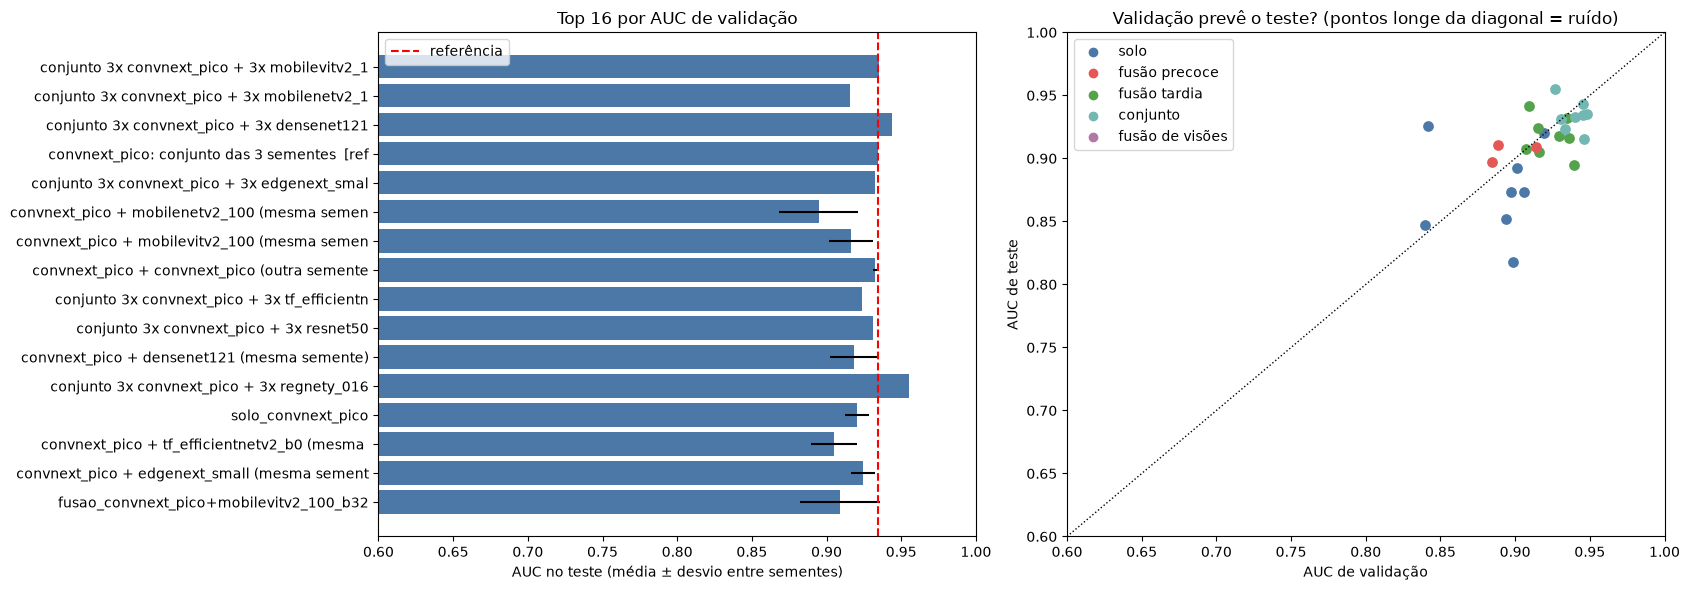

In [14]:
print("=== Todas as configurações (ordenadas por AUC de validação) ===")
imprimir_linhas()

ref_nome = f"{BACKBONE_BASE}: conjunto das {len(SEEDS)} sementes  [referência]"
ref = next((l for l in LINHAS if l["nome"] == ref_nome), None)
if ref is None:
    ref = next(l for l in LINHAS if l["nome"] == tag_base)
    print("\n(referência = média entre sementes do ConvNeXt-Pico solo)")

print(f"\n=== ΔAUC de teste vs. '{ref['nome']}' (bootstrap pareado, IC95%) ===")
topo = sorted([l for l in LINHAS if l is not ref], key=lambda l: -np.mean(l["val_auc"]))[:6]
for l in topo:
    d, (lo, hi) = ic_diff_auc(l["Pt_ens"], ref["Pt_ens"], Y_TEST)
    veredito = "diferença distinguível de ruído" if (lo > 0 or hi < 0) else "indistinguível de ruído"
    print(f"{l['nome'][:58]:58s} Δ={d:+.3f}  IC95%=[{lo:+.3f}, {hi:+.3f}]  -> {veredito}")

melhor = max(LINHAS, key=lambda l: np.mean(l["val_auc"]))
print(f"\nMelhor pela AUC de validação: {melhor['nome']}  (val {np.mean(melhor['val_auc']):.3f} | teste {np.mean(melhor['test_auc']):.3f})")

# gráficos: AUC de teste por configuração e confiabilidade da validação como preditor do teste
fig, axs = plt.subplots(1, 2, figsize=(17, 6))
ordem = sorted(LINHAS, key=lambda l: np.mean(l["val_auc"]))[-16:]
axs[0].barh([l["nome"][:44] for l in ordem], [np.mean(l["test_auc"]) for l in ordem],
            xerr=[np.std(l["test_auc"]) if len(l["test_auc"]) > 1 else 0 for l in ordem], color="#4C78A8")
axs[0].axvline(np.mean(ref["test_auc"]), color="red", ls="--", label="referência")
axs[0].set_xlim(0.6, 1.0); axs[0].set_xlabel("AUC no teste (média ± desvio entre sementes)")
axs[0].set_title("Top 16 por AUC de validação"); axs[0].legend()
cores = {"solo": "#4C78A8", "fusão precoce": "#E45756", "fusão tardia": "#54A24B", "conjunto": "#72B7B2", "fusão de visões": "#B279A2"}
for l in LINHAS:
    axs[1].scatter(np.mean(l["val_auc"]), np.mean(l["test_auc"]), color=cores.get(l["grupo"], "gray"), s=45)
lim = [0.6, 1.0]; axs[1].plot(lim, lim, "k:", lw=1)
axs[1].set_xlim(lim); axs[1].set_ylim(lim)
axs[1].set_xlabel("AUC de validação"); axs[1].set_ylabel("AUC de teste")
axs[1].set_title("Validação prevê o teste? (pontos longe da diagonal = ruído)")
for g, c in cores.items():
    axs[1].scatter([], [], color=c, label=g)
axs[1].legend()
plt.tight_layout()
plt.show()

## 14. Modelo final e avaliação no teste

`FINAL_MODELOS` (Seção 2) define o modelo usado daqui em diante: a **média das probabilidades de todas as sementes**
das tags listadas (como no fluxo final do repositório, que usa 3 sementes). O padrão é o ConvNeXt-Pico sozinho. Se
a Seção 13 mostrar uma configuração melhor **na validação** e com ΔAUC distinguível de ruído, troque a lista, por
exemplo `["solo_convnext_pico", "solo_tf_efficientnetv2_b0"]` (fusão tardia).

Modelo final = média de 3 modelos: ['solo_convnext_pico'] x sementes [42, 43, 44]
sem TTA         acc 0.8716 | prec 0.8716 | rec 0.8716 | F1 0.8716 | AUC 0.9341
com TTA (flip)  acc 0.8899 | prec 0.8899 | rec 0.8899 | F1 0.8899 | AUC 0.9486

              precision    recall  f1-score   support

       MILCO       0.91      0.91      0.91        75
       NOMBO       0.79      0.79      0.79        34

    accuracy                           0.87       109
   macro avg       0.85      0.85      0.85       109
weighted avg       0.87      0.87      0.87       109



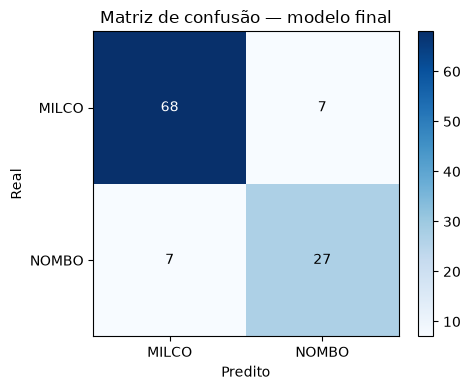

In [15]:
for t in FINAL_MODELOS:
    assert t in RES, f"Tag '{t}' não foi treinada. Tags disponíveis: {list(RES)}"

modelos_finais = [carregar_modelo(t, s) for t in FINAL_MODELOS for s in SEEDS]
fusion_model = ConjuntoMedia(modelos_finais).to(device).eval()    # nome usado pelas células 15 e 16
print(f"Modelo final = média de {len(modelos_finais)} modelos: {FINAL_MODELOS} x sementes {SEEDS}")

transform_classificacao = transform_eval
for rotulo, tta in (("sem TTA", False), ("com TTA (flip)", True)):
    P = prever(fusion_model, DADOS["X_test"], tta=tta)
    y_pred = P.argmax(1)
    prec, rec, f1, _ = precision_recall_fscore_support(Y_TEST, y_pred, average="weighted", zero_division=0)
    print(f"{rotulo:15s} acc {accuracy_score(Y_TEST, y_pred):.4f} | prec {prec:.4f} | rec {rec:.4f} | "
          f"F1 {f1:.4f} | AUC {auc_milco_nombo(Y_TEST, P):.4f}")

P = prever(fusion_model, DADOS["X_test"])
y_pred = P.argmax(1)
print()
print(classification_report(Y_TEST, y_pred, target_names=CLASS_NAMES, zero_division=0))
cm = confusion_matrix(Y_TEST, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASS_NAMES))); ax.set_xticklabels(CLASS_NAMES)
ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predito"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusão — modelo final")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im); plt.tight_layout(); plt.show()

## 15. Grade de recortes — real x predito (4x4)

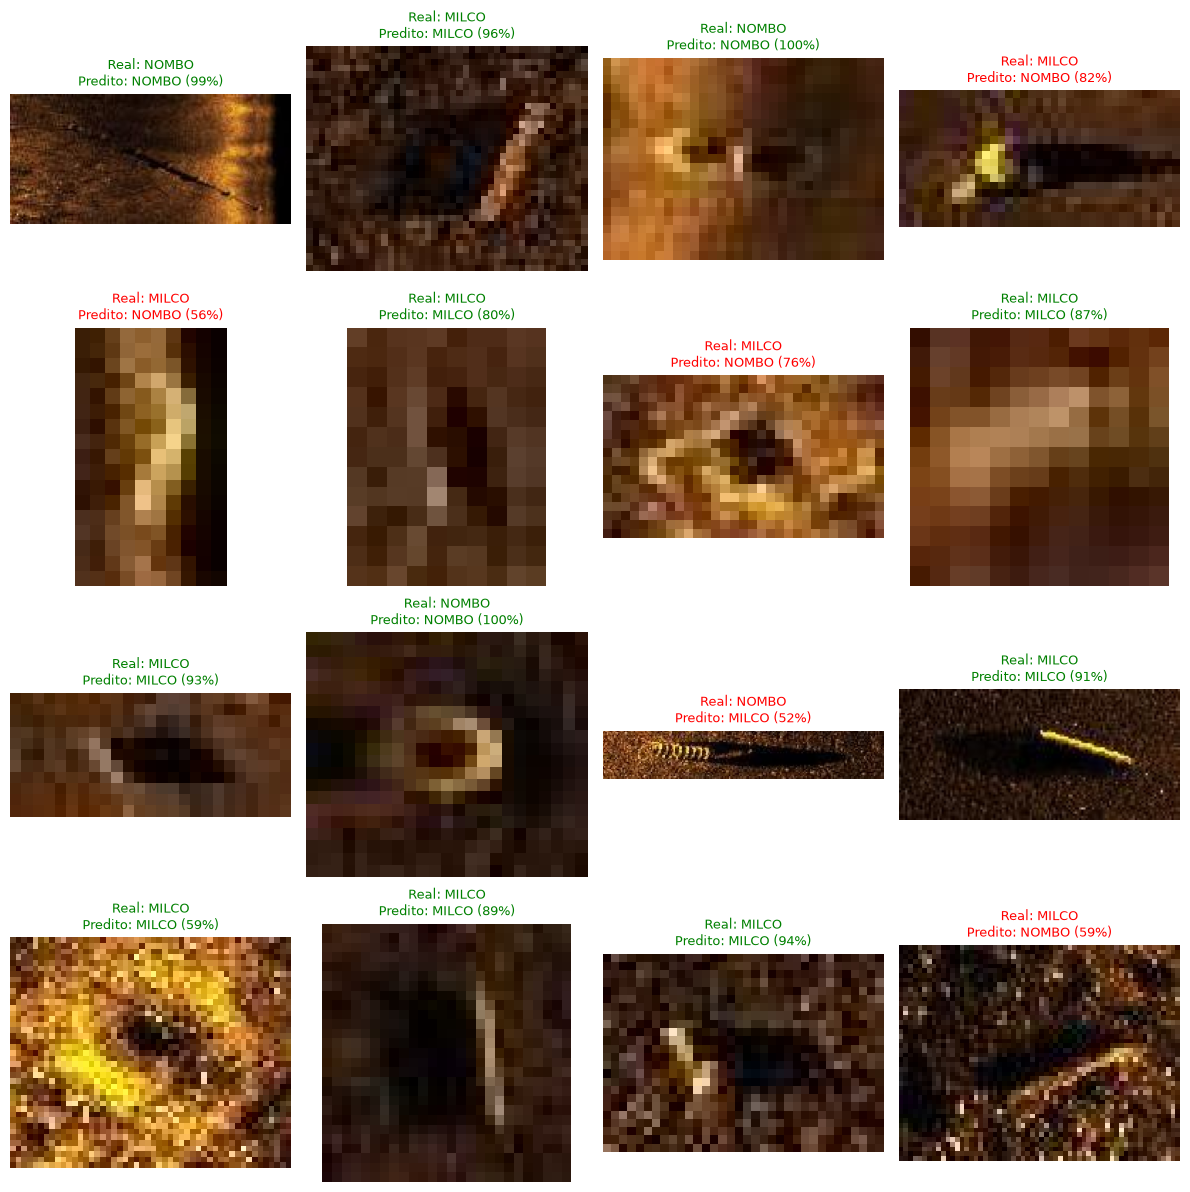

In [16]:

transform_classificacao = transform_eval

@torch.no_grad()
def classificar_recorte(caminho_recorte):
    img = Image.open(caminho_recorte).convert("RGB")
    tensor = transform_classificacao(img).unsqueeze(0).to(device)
    probs = torch.softmax(fusion_model(tensor), dim=1)[0].cpu().numpy()
    idx = int(np.argmax(probs))
    return CLASS_NAMES[idx], float(probs[idx])


def plotar_grade_recortes(dataset, n_linhas=4, n_colunas=4, seed=0):
    rnd = random.Random(seed)
    indices = rnd.sample(range(len(dataset.samples)), min(n_linhas * n_colunas, len(dataset.samples)))

    fig, axs = plt.subplots(n_linhas, n_colunas, figsize=(3 * n_colunas, 3 * n_linhas))
    axs = axs.flatten()

    for ax, idx in zip(axs, indices):
        caminho, classe_real_idx = dataset.samples[idx]
        classe_real = CLASS_NAMES[classe_real_idx]
        classe_predita, confianca = classificar_recorte(caminho)

        img = Image.open(caminho).convert("RGB")
        ax.imshow(img)
        cor = "green" if classe_predita == classe_real else "red"
        ax.set_title(f"Real: {classe_real}\nPredito: {classe_predita} ({confianca*100:.0f}%)",
                     fontsize=9, color=cor)
        ax.axis("off")

    for ax in axs[len(indices):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


plotar_grade_recortes(ds_test_cls, n_linhas=4, n_colunas=4)


## 16. Pipeline fim-a-fim: YOLO (detecção) + fusão (classificação), com caixa desenhada

Aponte `CAMINHO_PESOS_YOLO` para o `best.pt` do modelo que você escolher (Modelo A ou B, o que
teve melhor `AR_small`/mAP na comparação do outro notebook).

In [17]:

from ultralytics import YOLO

CAMINHO_PESOS_YOLO = Path(r"D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelA_yolo_p2\weights\best.pt") # <-- ajuste
detector = YOLO(CAMINHO_PESOS_YOLO)


@torch.no_grad()
def detectar_e_classificar(imagem_path, score_thresh=0.5, margin=CROP_MARGIN):
    img = Image.open(imagem_path).convert("RGB")
    w, h = img.size

    saida_yolo = detector.predict(source=str(imagem_path), conf=score_thresh, verbose=False)[0]

    resultados = []
    for box in saida_yolo.boxes:
        xmin, ymin, xmax, ymax = box.xyxy[0].tolist()
        score = float(box.conf[0])
        bw, bh = xmax - xmin, ymax - ymin

        xmin_m = max(0, xmin - bw * margin)
        ymin_m = max(0, ymin - bh * margin)
        xmax_m = min(w, xmax + bw * margin)
        ymax_m = min(h, ymax + bh * margin)

        crop = img.crop((xmin_m, ymin_m, xmax_m, ymax_m))
        crop_tensor = transform_classificacao(crop).unsqueeze(0).to(device)
        probs = torch.softmax(fusion_model(crop_tensor), dim=1)[0].cpu().numpy()
        classe_idx = int(np.argmax(probs))

        resultados.append({
            "box": (xmin, ymin, xmax, ymax),
            "score_deteccao": score,
            "classe": CLASS_NAMES[classe_idx],
            "confianca_classificacao": float(probs[classe_idx]),
        })

    return img, resultados


def plotar_resultado(img, resultados, titulo=None):
    cores = {"MILCO": "cyan", "NOMBO": "yellow"}
    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(img)
    for r in resultados:
        xmin, ymin, xmax, ymax = r["box"]
        cor = cores.get(r["classe"], "red")
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                  linewidth=2, edgecolor=cor, facecolor="none")
        ax.add_patch(rect)
        rotulo = f"{r['classe']} ({r['confianca_classificacao']*100:.1f}%)"
        ax.text(xmin, max(ymin - 5, 0), rotulo, color=cor, fontsize=10, weight="bold",
                bbox=dict(facecolor="black", alpha=0.4, pad=1))
    ax.axis("off")
    if titulo:
        ax.set_title(titulo)
    plt.show()


0001_2015.jpg -> [{'box': (79.6243667602539, 212.3608856201172, 131.77432250976562, 250.9516143798828), 'score_deteccao': 0.9273697137832642, 'classe': 'MILCO', 'confianca_classificacao': 0.9564728140830994}, {'box': (911.7950439453125, 966.5802001953125, 965.6376342773438, 998.6981811523438), 'score_deteccao': 0.7582631707191467, 'classe': 'NOMBO', 'confianca_classificacao': 0.7518206834793091}]
0002_2015.jpg -> [{'box': (174.6575469970703, 296.97747802734375, 184.61927795410156, 312.85565185546875), 'score_deteccao': 0.7918393015861511, 'classe': 'MILCO', 'confianca_classificacao': 0.6086629033088684}, {'box': (324.91204833984375, 401.6396179199219, 345.9027099609375, 412.13671875), 'score_deteccao': 0.7498466372489929, 'classe': 'MILCO', 'confianca_classificacao': 0.9215190410614014}, {'box': (369.9436950683594, 58.97100067138672, 392.19818115234375, 73.10289764404297), 'score_deteccao': 0.710652232170105, 'classe': 'NOMBO', 'confianca_classificacao': 0.6637112498283386}, {'box': (3

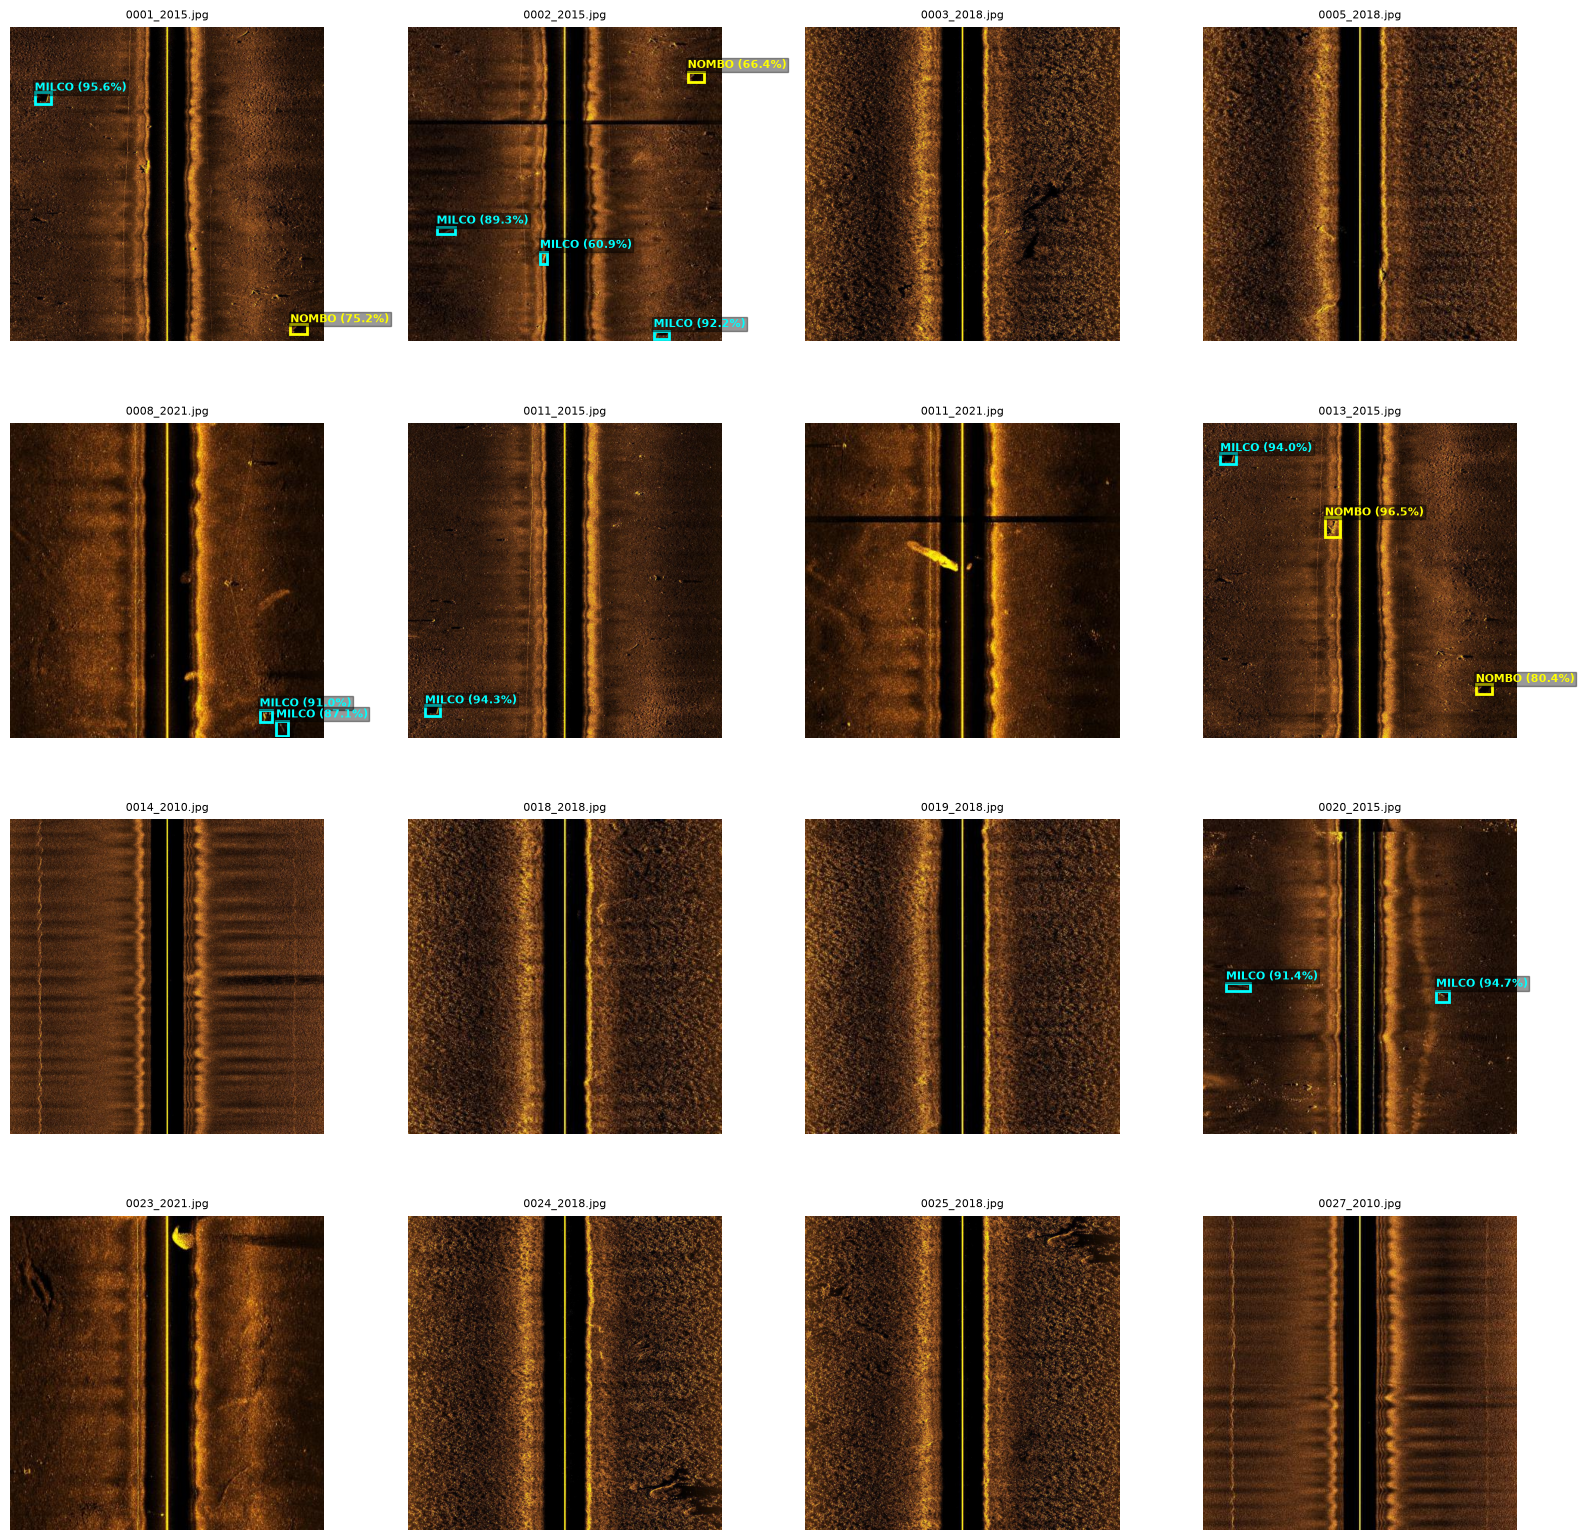

In [18]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Ajuste leve na sua função plotar_resultado para aceitar 'ax'
def plotar_resultado(img, resultados, titulo=None, ax=None):
    cores = {"MILCO": "cyan", "NOMBO": "yellow"}
    
    # Se nenhum eixo for passado, cria uma figura individual (mantém o comportamento original)
    if ax is None:
        fig, ax = plt.subplots(1, figsize=(8, 8))
        mostrar_no_final = True
    else:
        mostrar_no_final = False

    ax.imshow(img)
    
    for r in resultados:
        xmin, ymin, xmax, ymax = r["box"]
        cor = cores.get(r["classe"], "red")
        
        rect = patches.Rectangle(
            (xmin, ymin), xmax - xmin, ymax - ymin,
            linewidth=2, edgecolor=cor, facecolor="none"
        )
        ax.add_patch(rect)
        
        rotulo = f"{r['classe']} ({r['confianca_classificacao']*100:.1f}%)"
        ax.text(
            xmin, max(ymin - 5, 0), rotulo, color=cor, fontsize=8, weight="bold",
            bbox=dict(facecolor="black", alpha=0.4, pad=1)
        )
        
    ax.axis("off")
    if titulo:
        ax.set_title(titulo, fontsize=8)
        
    if mostrar_no_final:
        plt.show()


# 2. Execução da grade 4x4 (16 imagens)
imagens_teste_completas = sorted((YOLO_DIR / "images" / "test").glob("*.jpg"))[:16]

# Cria o painel 4x4 de uma só vez
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes_flat = axes.flatten()

for i, img_path in enumerate(imagens_teste_completas):
    img, resultados = detectar_e_classificar(img_path, score_thresh=0.5)
    
    # Passa o eixo específico da grade (axes_flat[i]) para a função desenhar nele
    plotar_resultado(img, resultados, titulo=img_path.name, ax=axes_flat[i])
    print(img_path.name, "->", resultados)

# Desativa eixos vazios caso haja menos de 16 imagens na pasta
for j in range(len(imagens_teste_completas), 16):
    axes_flat[j].axis("off")

plt.tight_layout()
plt.show()

## Como ler os resultados

- **Seção 8:** parceiros reprovados na triagem raramente valem a fusão (evidência do repositório).
- **Seção 9:** se `ConvNeXt + parceiro` supera `ConvNeXt + ConvNeXt (outra semente)`, o parceiro traz informação nova.
- **Seção 10:** compare `b12` × `b32` (efeito do batch) e `b32` × `robusta` (efeito das salvaguardas).
- **Seção 12:** `ρ(fusão, base)` baixo + confiança alta + ablação mostrando um ramo dominante = fusão ruim por
  superajuste/desbalanceio entre ramos.
- **Seção 13:** só considere uma melhoria real se o IC95% do ΔAUC não incluir 0 **e** a validação também apontar a
  mesma configuração.
- Pesos pré-treinados vêm do hub do `timm` (precisa de internet na primeira execução de cada modelo).